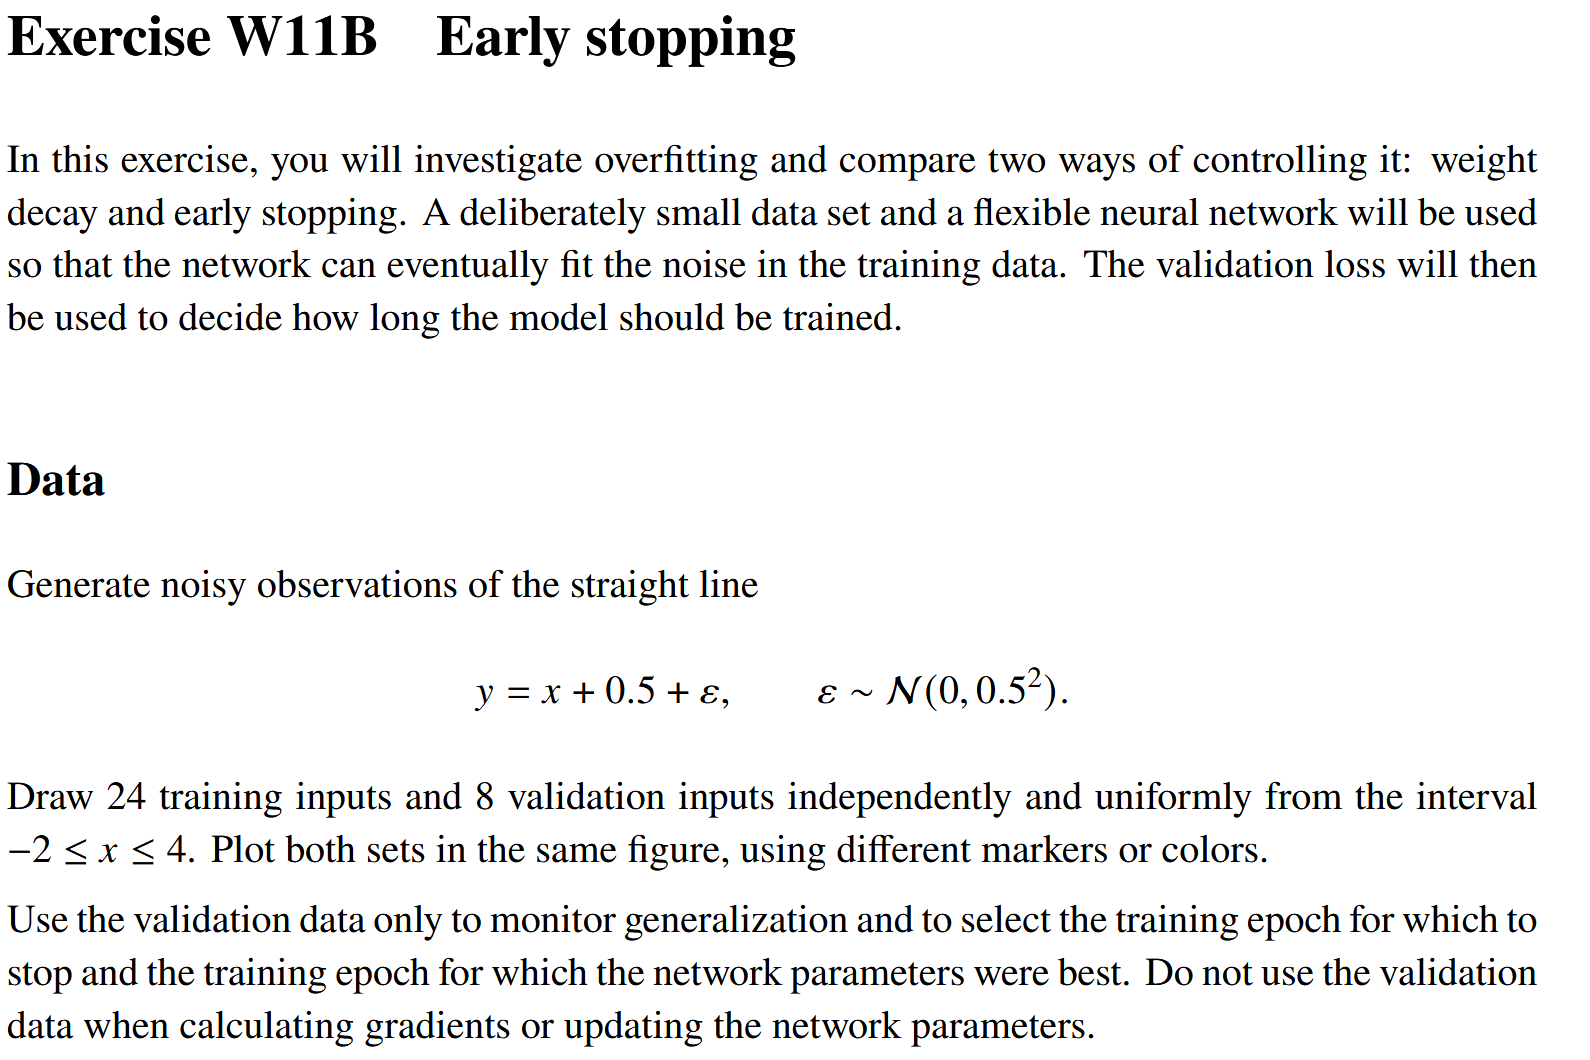

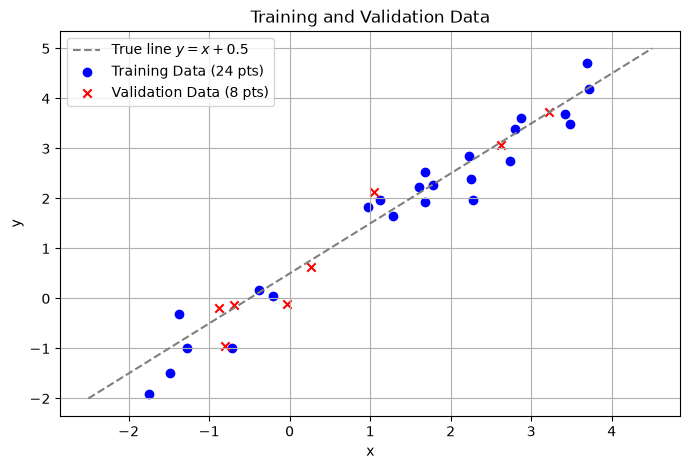

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from models import *

n_train = 24
n_val = 8

x_train = np.random.uniform(-2, 4, n_train)
noise_train = np.random.normal(0, 0.5, n_train)
y_train = x_train + 0.5 + noise_train

x_val = np.random.uniform(-2, 4, n_val)
noise_val = np.random.normal(0, 0.5, n_val)
y_val = x_val + 0.5 + noise_val

x_true = np.linspace(-2.5, 4.5, 100)
y_true = x_true + 0.5

plt.figure(figsize=(8, 5))
plt.plot(x_true, y_true, label='True line $y = x + 0.5$', color='gray', linestyle='--')
plt.scatter(x_train, y_train, label='Training Data (24 pts)', color='blue', marker='o')
plt.scatter(x_val, y_val, label='Validation Data (8 pts)', color='red', marker='x')

plt.title('Training and Validation Data')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

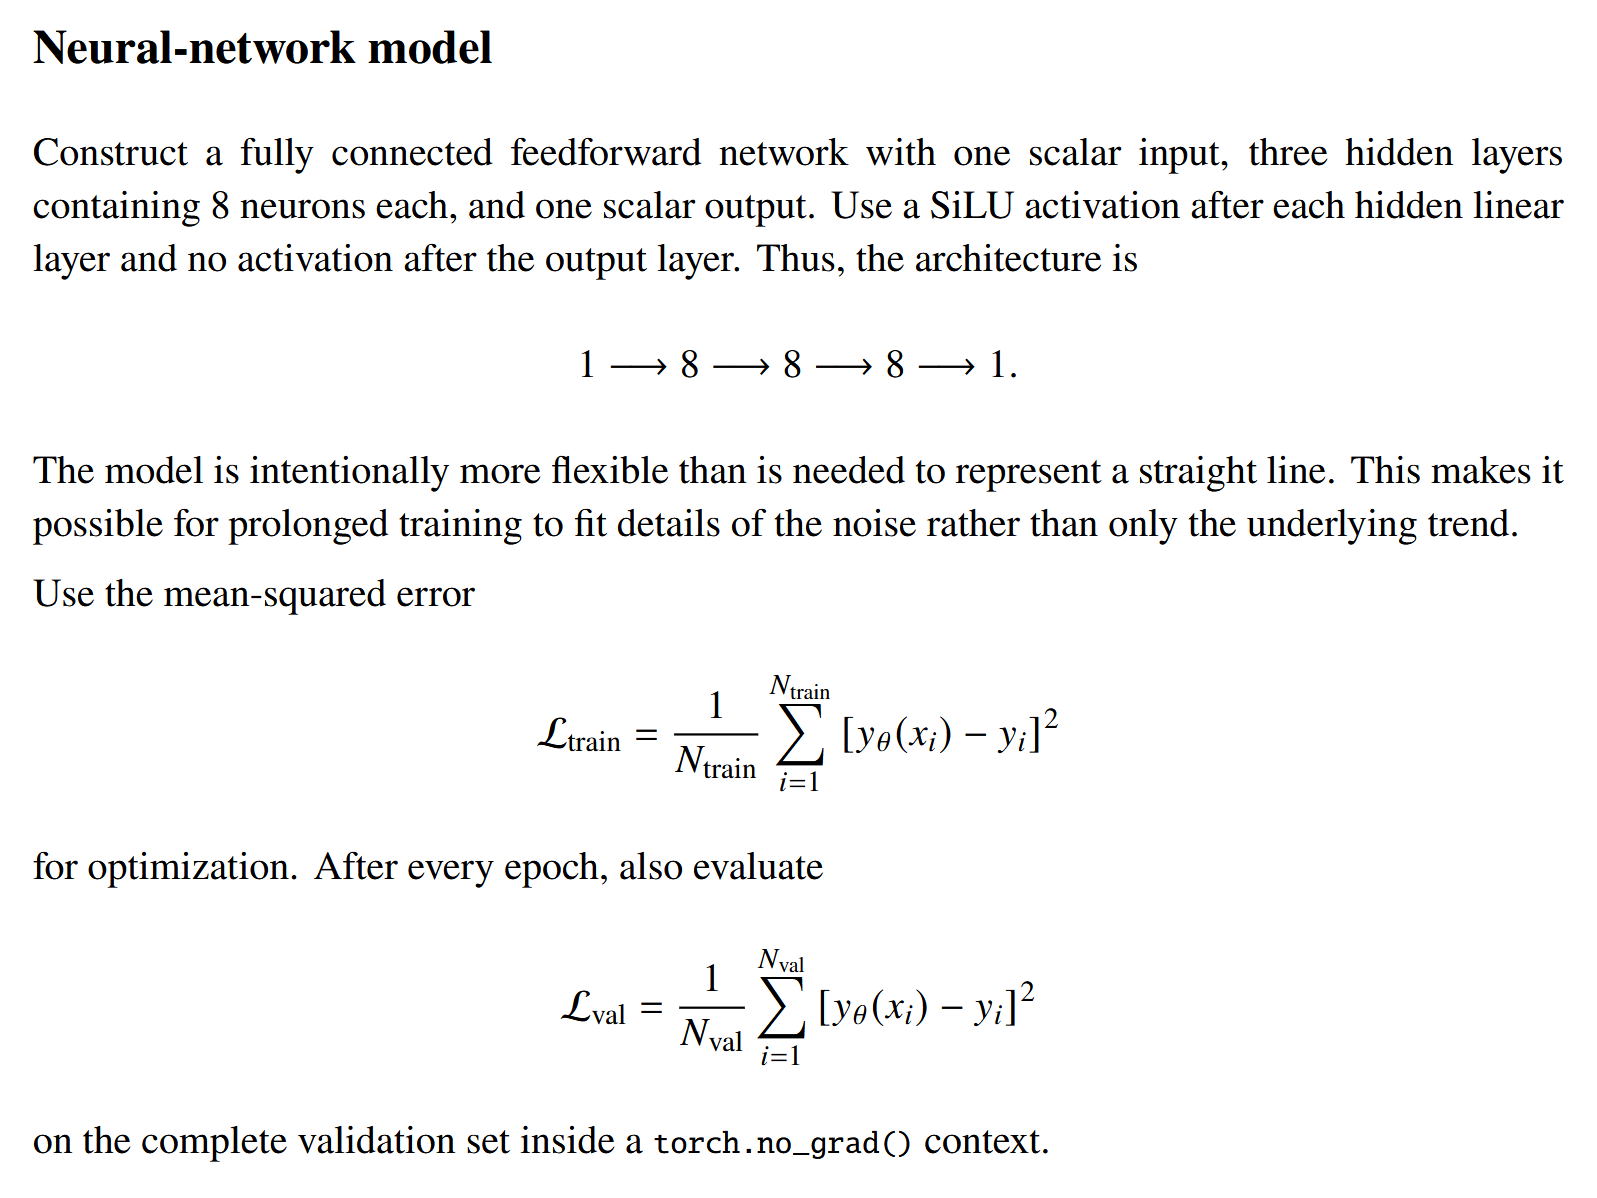

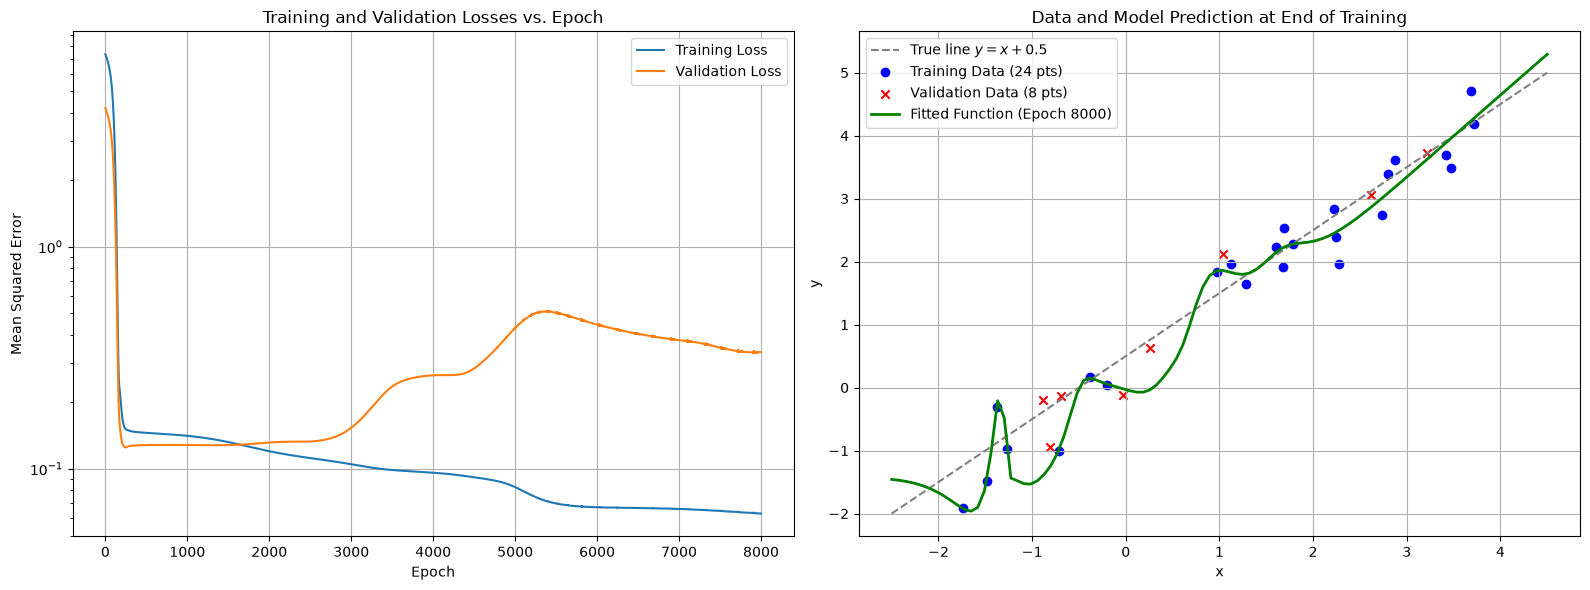

In [4]:
X_train_t = torch.tensor(x_train, dtype=torch.float32)
Y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(x_val, dtype=torch.float32)
Y_val_t = torch.tensor(y_val, dtype=torch.float32)
X_true_t = torch.tensor(x_true, dtype=torch.float32)

model = LinearSiLUModule(hidden=8, layers=2)

optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=0.0)
criterion = nn.MSELoss()

epochs = 8000 
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    y_pred = model(X_train_t)
    train_loss = criterion(y_pred, Y_train_t)
    train_loss.backward()
    optimizer.step()
    
    train_losses.append(train_loss.item())
    
    model.eval()
    with torch.no_grad():
        val_pred = model(X_val_t)
        val_loss = criterion(val_pred, Y_val_t)
        val_losses.append(val_loss.item())

model.eval()
with torch.no_grad():
    y_fit = model(X_true_t).squeeze().numpy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(train_losses, label='Training Loss')
axes[0].plot(val_losses, label='Validation Loss')
axes[0].set_yscale('log')
axes[0].set_title('Training and Validation Losses vs. Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Mean Squared Error')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(x_true, y_true, label='True line $y = x + 0.5$', color='gray', linestyle='--')
axes[1].scatter(x_train, y_train, label='Training Data (24 pts)', color='blue', marker='o')
axes[1].scatter(x_val, y_val, label='Validation Data (8 pts)', color='red', marker='x')
axes[1].plot(x_true, y_fit, label='Fitted Function (Epoch 8000)', color='green', linewidth=2)
axes[1].set_title('Data and Model Prediction at End of Training')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Discussion Questions

* **Why can the training loss continue to decrease while the validation loss increases?**
Because the network is highly flexible, it stops learning the general trend of the data and begins memorizing the random noise specific to the training set. As it fits this noise perfectly, the training loss approaches zero, but the model's ability to generalize degrades, causing the error on the unseen validation set to rise.


* **What features of the final fitted curve indicate that the network has started to fit noise in the training set?**
The fitted curve will exhibit highly non-linear, jagged, or wavy behaviors that aggressively zig-zag to pass exactly through the training data points, completely abandoning the underlying straight-line trend.


* **Why is the epoch with the smallest training loss not necessarily the best choice for predictions on new data?**
The epoch with the smallest training loss represents the point of maximum overfitting. A model at this epoch is hyper-specialized to the noise in the training set and will make highly inaccurate predictions on new, unseen data, which is reflected in a high validation loss.

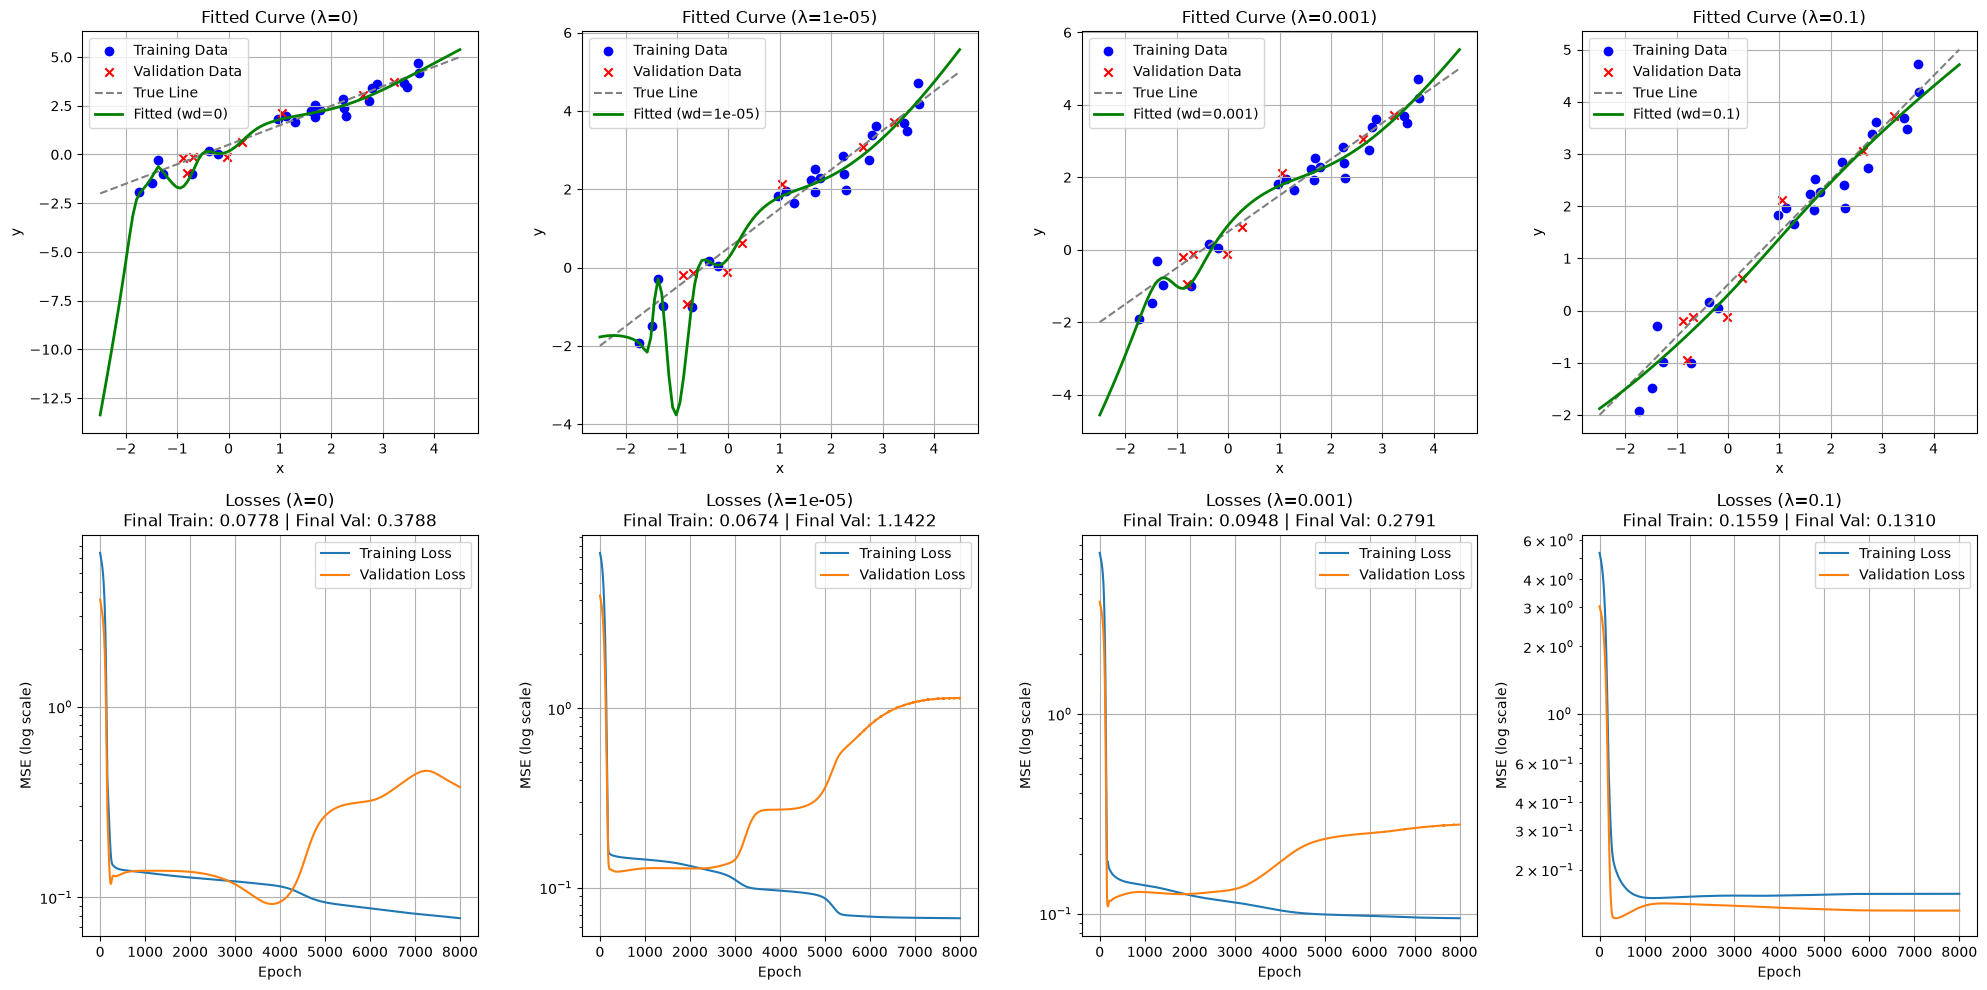

In [7]:
lambdas = [0, 1e-5, 1e-3, 1e-1]
epochs = 5000

fig, axes = plt.subplots(2, len(lambdas), figsize=(20, 10))

for idx, wd in enumerate(lambdas):
    model = LinearSiLUModule(hidden=8, layers=2)
    
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=wd)
    criterion = nn.MSELoss()
    
    train_losses = []
    val_losses = []
    
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        y_pred = model(X_train_t)
        loss = criterion(y_pred, Y_train_t)
        loss.backward()
        optimizer.step()
        
        train_losses.append(loss.item())
        
        model.eval()
        with torch.no_grad():
            val_pred = model(X_val_t)
            v_loss = criterion(val_pred, Y_val_t)
            val_losses.append(v_loss.item())
            
    model.eval()
    with torch.no_grad():
        y_fit = model(X_true_t).squeeze().numpy()
        
    final_train_loss = train_losses[-1]
    final_val_loss = val_losses[-1]
    
    ax_fit = axes[0, idx]
    ax_fit.scatter(x_train, y_train, label='Training Data', color='blue')
    ax_fit.scatter(x_val, y_val, label='Validation Data', color='red', marker='x')
    ax_fit.plot(x_true, y_true, label='True Line', color='gray', linestyle='--')
    ax_fit.plot(x_true, y_fit, label=f'Fitted (wd={wd})', color='green', linewidth=2)
    ax_fit.set_title(f'Fitted Curve (λ={wd})')
    ax_fit.set_xlabel('x')
    ax_fit.set_ylabel('y')
    ax_fit.legend()
    ax_fit.grid(True)
    
    ax_loss = axes[1, idx]
    ax_loss.plot(train_losses, label='Training Loss')
    ax_loss.plot(val_losses, label='Validation Loss')
    ax_loss.set_yscale('log')
    ax_loss.set_title(f'Losses (λ={wd})\nFinal Train: {final_train_loss:.4f} | Final Val: {final_val_loss:.4f}')
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('MSE (log scale)')
    ax_loss.legend()
    ax_loss.grid(True)

plt.tight_layout()
plt.show()

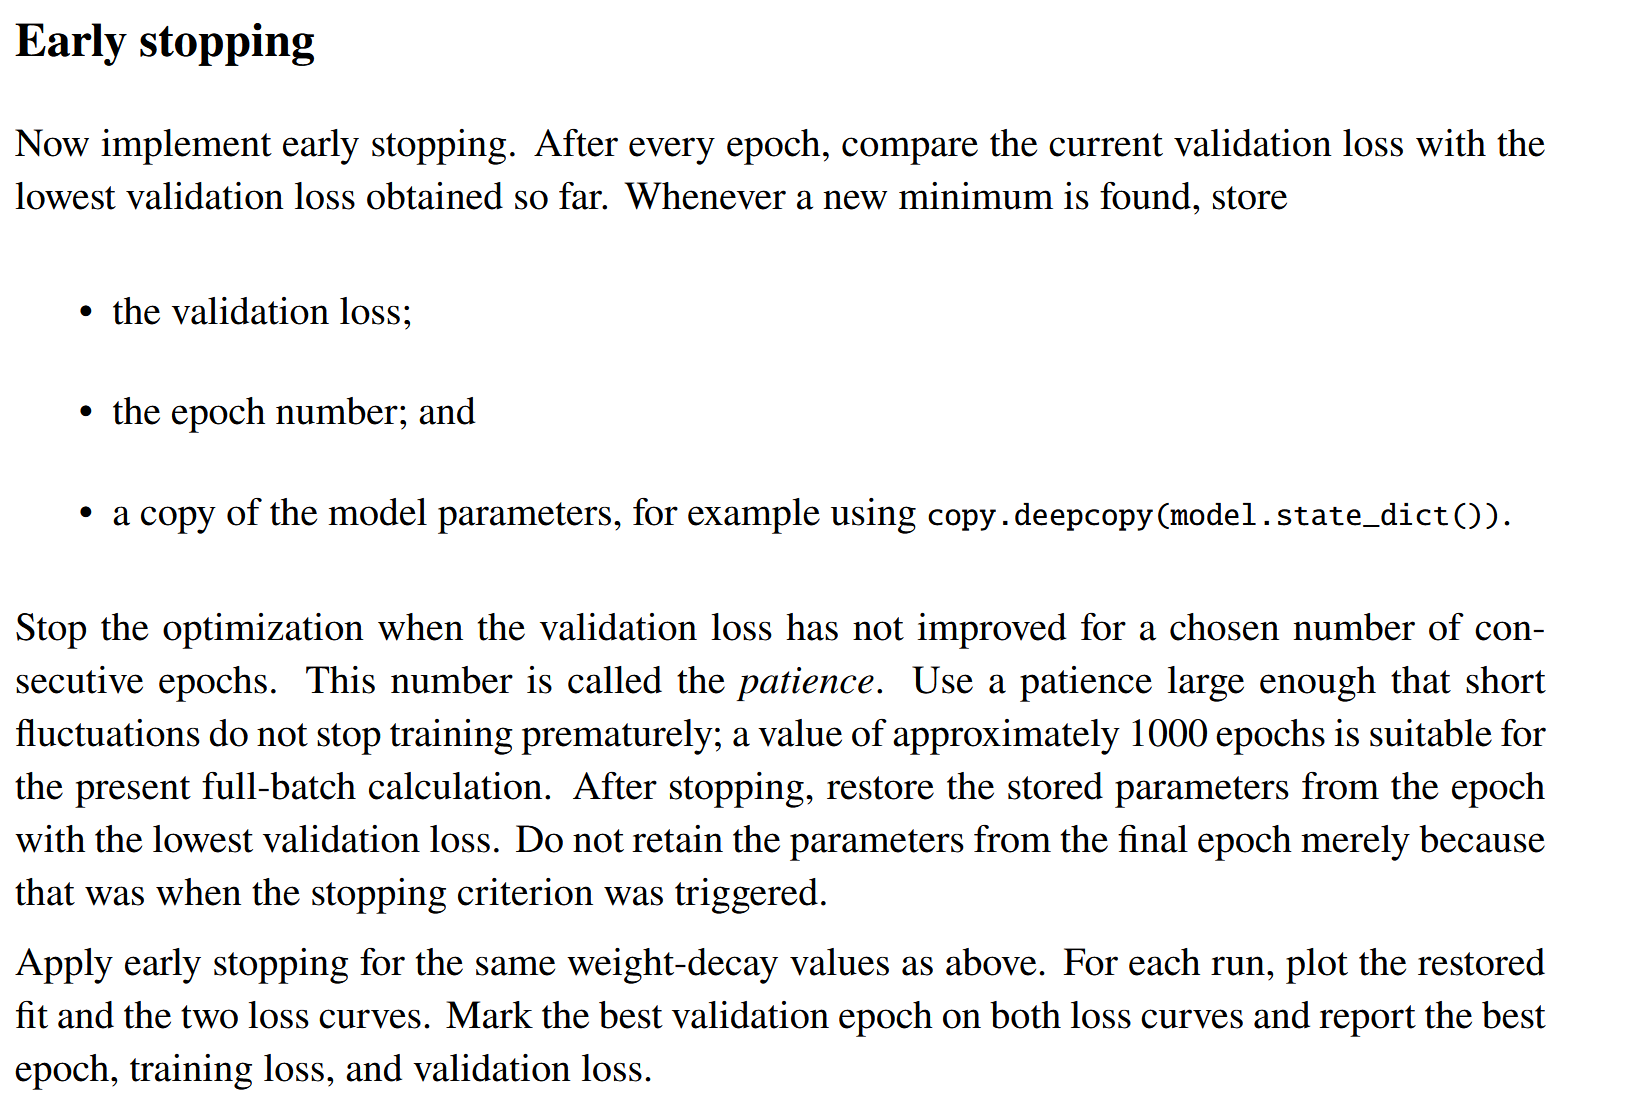

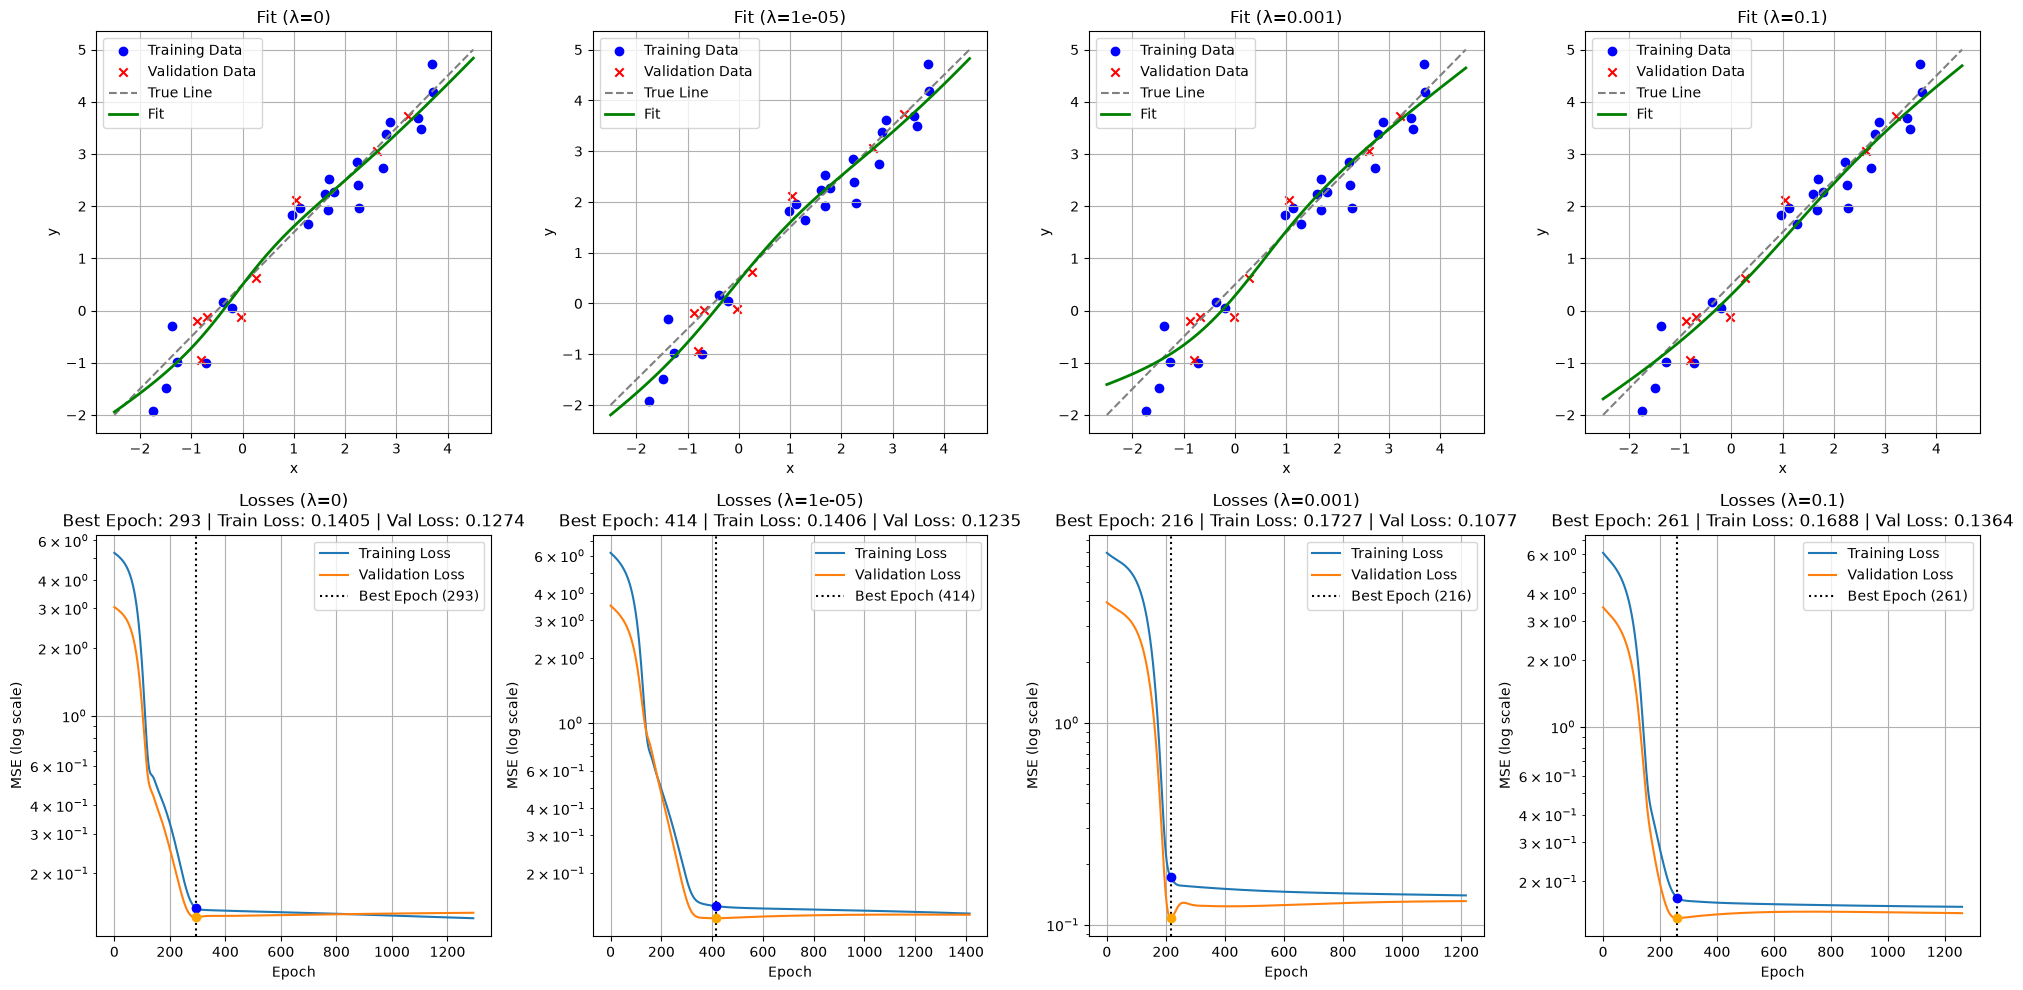

In [11]:
import copy

lambdas = [0, 1e-5, 1e-3, 1e-1]
patience = 1000
max_epochs = 15000

fig, axes = plt.subplots(2, len(lambdas), figsize=(20, 10))

for idx, wd in enumerate(lambdas):
    model = LinearSiLUModule(hidden=8, layers=2)
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=wd)
    criterion = nn.MSELoss()
    
    train_losses = []
    val_losses = []
    
    best_val_loss = float('inf')
    best_train_loss = float('inf')
    best_epoch = -1
    best_model_state = None
    epochs_no_improve = 0
    
    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        y_pred = model(X_train_t)
        loss = criterion(y_pred, Y_train_t)
        loss.backward()
        optimizer.step()
        
        train_losses.append(loss.item())
        
        model.eval()
        with torch.no_grad():
            val_pred = model(X_val_t)
            v_loss = criterion(val_pred, Y_val_t)
            val_losses.append(v_loss.item())
            
        if v_loss.item() < best_val_loss:
            best_val_loss = v_loss.item()
            best_train_loss = loss.item()
            best_epoch = epoch
            best_model_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            
        if epochs_no_improve >= patience:
            break
            
    model.load_state_dict(best_model_state)
    
    model.eval()
    with torch.no_grad():
        y_fit = model(X_true_t).squeeze().numpy()
        
    ax_fit = axes[0, idx]
    ax_fit.scatter(x_train, y_train, label='Training Data', color='blue')
    ax_fit.scatter(x_val, y_val, label='Validation Data', color='red', marker='x')
    ax_fit.plot(x_true, y_true, label='True Line', color='gray', linestyle='--')
    ax_fit.plot(x_true, y_fit, label=f'Fit', color='green', linewidth=2)
    ax_fit.set_title(f'Fit (λ={wd})')
    ax_fit.set_xlabel('x')
    ax_fit.set_ylabel('y')
    ax_fit.legend()
    ax_fit.grid(True)
    
    ax_loss = axes[1, idx]
    ax_loss.plot(train_losses, label='Training Loss')
    ax_loss.plot(val_losses, label='Validation Loss')
    ax_loss.axvline(x=best_epoch, color='k', linestyle=':', label=f'Best Epoch ({best_epoch})')
    ax_loss.scatter([best_epoch], [best_train_loss], color='blue', zorder=5)
    ax_loss.scatter([best_epoch], [best_val_loss], color='orange', zorder=5)
    ax_loss.set_yscale('log')
    ax_loss.set_title(f'Losses (λ={wd})\nBest Epoch: {best_epoch} | Train Loss: {best_train_loss:.4f} | Val Loss: {best_val_loss:.4f}')
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('MSE (log scale)')
    ax_loss.legend()
    ax_loss.grid(True)

plt.tight_layout()
plt.show()

* **Prevention of overfitting:** Early stopping monitors the model's generalization ability and halts the training process before the optimizer has enough time to perfectly memorize the training set. By stopping exactly when the validation loss begins to rise, it prevents the weights from reaching the strongly overfitted solution seen in prolonged training.


* **Early stopping vs. weight decay:** Early stopping does not render weight decay unnecessary. A combination of the two often yields the best validation loss because weight decay restricts the model's complexity and smooths the learned function during the learning process, while early stopping acts as a safety mechanism to halt training when that regularized model eventually starts fitting noise.


* **Role of the patience parameter:** The patience parameter determines how many consecutive epochs the optimizer is allowed to run without seeing an improvement in validation loss. If the patience is too small, training may terminate prematurely due to normal, brief fluctuations in the loss curve. If the patience is too large, the system wastes computational resources continuing to train long after the model has begun significantly overfitting.


* **Restoring best parameters:** The early stopping criterion is only triggered *after* the validation loss has continuously degraded for the duration of the patience window. Consequently, the model state at the final epoch is overfitted and performs poorly; the parameters must be restored to the specific epoch where the minimum validation loss was actually recorded.


* **Role of a separate test set:** A test set must provide a strictly unbiased evaluation of the final model's performance on unseen data. If a test set is used to tune the weight decay parameter or to decide the early stopping point, its information leaks into the training process (turning it into a validation set), which invalidates its use as an objective final benchmark.


Early stopping acts as a powerful form of implicit regularization because it strictly limits how closely the network can adapt to the finite training sample. By restricting the total number of optimization steps, the network is not given enough time to grow its parameters to the magnitudes required to perfectly trace the high-frequency noise in the data, achieving the same smoothing effect as an explicit mathematical penalty on the loss function.